In [1]:
# 1. Instalación y Configuración del Entorno
# Instalamos la librería 'datasets' de Hugging Face
!pip install datasets -q

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from datasets import load_dataset
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, SimpleRNN, LSTM, Dense, Dropout, Bidirectional
from sklearn.metrics import classification_report, confusion_matrix

# Configuración de estilos para gráficas
sns.set_style("whitegrid")

# Carga y Preprocesamiento de Datos

Aquí implementamos la tokenización y el padding. Nota: Al definir MAX_LENGTH, estamos configurando implícitamente el Truncated Backpropagation Through Time (BPTT). La red solo propagará el error 100 pasos hacia atrás, suficiente para frases cortas.

In [2]:
# Carga y Preprocesamiento (Tokenización y Padding)

# 1. Cargar Dataset: Usamos 'dair-ai/emotion' (estándar académico)
# Etiquetas: 0:sadness, 1:joy, 2:love, 3:anger, 4:fear, 5:surprise
dataset = load_dataset("dair-ai/emotion")

train_texts = dataset['train']['text']
train_labels = np.array(dataset['train']['label'])
test_texts = dataset['test']['text']
test_labels = np.array(dataset['test']['label'])

label_names = ['tristeza', 'alegría', 'amor', 'ira', 'miedo', 'sorpresa']

# 2. Tokenización
VOCAB_SIZE = 10000  # Consideramos las 10k palabras más frecuentes
OOV_TOK = "<OOV>"   # Token para palabras desconocidas

tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOK)
tokenizer.fit_on_texts(train_texts)

# 3. Conversión a Secuencias y Padding (Truncated BPTT)
# Limitamos las secuencias a 100 tokens. Esto actúa como BPTT truncado.
MAX_LENGTH = 100
PADDING_TYPE = 'post'
TRUNC_TYPE = 'post'

train_sequences = tokenizer.texts_to_sequences(train_texts)
train_padded = pad_sequences(train_sequences, maxlen=MAX_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)

test_sequences = tokenizer.texts_to_sequences(test_texts)
test_padded = pad_sequences(test_sequences, maxlen=MAX_LENGTH, padding=PADDING_TYPE, truncating=TRUNC_TYPE)

print(f"Dimensión datos de entrenamiento: {train_padded.shape}")
print(f"Ejemplo de texto: {train_texts[0]}")
print(f"Ejemplo tokenizado y padded: {train_padded[0]}")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

split/train-00000-of-00001.parquet:   0%|          | 0.00/1.03M [00:00<?, ?B/s]

split/validation-00000-of-00001.parquet:   0%|          | 0.00/127k [00:00<?, ?B/s]

split/test-00000-of-00001.parquet:   0%|          | 0.00/129k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/16000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/2000 [00:00<?, ? examples/s]

Dimensión datos de entrenamiento: (16000, 100)
Ejemplo de texto: i didnt feel humiliated
Ejemplo tokenizado y padded: [  2 139   3 679   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0   0
   0   0   0   0   0   0   0   0   0   0]


# Definición de Arquitecturas (RNN vs LSTM)

In [3]:
# Definición de Arquitecturas Secuenciales

# Dimensión de los vectores de palabras
EMBEDDING_DIM = 64

# --- MODELO A: RNN Tradicional (SimpleRNN) ---
# Justificación: Modelo base para demostrar el manejo de secuencias simples.
# Limitación esperada: Problema de desvanecimiento del gradiente en frases largas.
def build_simple_rnn():
    model = Sequential([
        Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),
        SimpleRNN(64, return_sequences=False), # False porque es clasificación many-to-one
        Dropout(0.5), # Regularización para evitar overfitting
        Dense(64, activation='relu'),
        Dense(6, activation='softmax') # 6 neuronas para 6 emociones
    ])
    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

# --- MODELO B: LSTM (Long Short-Term Memory) ---
# Justificación: Introduce celdas de memoria y compuertas (forget, input, output)
# para aprender dependencias a largo plazo y mitigar el desvanecimiento del gradiente.
# Usamos Bidireccional para capturar contexto pasado y futuro.
def build_lstm():
    model = Sequential([
        Embedding(VOCAB_SIZE, EMBEDDING_DIM, input_length=MAX_LENGTH),
        Bidirectional(LSTM(64)), # Bidireccional mejora la comprensión del contexto
        Dropout(0.5),
        Dense(64, activation='relu'),
        Dense(6, activation='softmax')
    ])
    model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
    return model

model_rnn = build_simple_rnn()
model_lstm = build_lstm()

print("--- Arquitectura RNN Simple ---")
model_rnn.summary()
print("\n--- Arquitectura LSTM Bidireccional ---")
model_lstm.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


--- Arquitectura RNN Simple ---


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

... (3 outputs left out)

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# Entrenamiento de Modelos
Entrenamos ambos modelos bajo las mismas condiciones para que la comparación sea justa.

In [4]:
# Entrenamiento de Modelos
EPOCHS = 10
BATCH_SIZE = 64

history_rnn = model_rnn.fit(
    train_padded, train_labels,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(test_padded, test_labels),
    verbose=1
)

history_lstm = model_lstm.fit(
    train_padded, train_labels,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_data=(test_padded, test_labels),
    verbose=1
)

Epoch 1/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.3118 - loss: 1.6347 - val_accuracy: 0.3475 - val_loss: 1.5604
Epoch 2/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3193 - loss: 1.5810 - val_accuracy: 0.3475 - val_loss: 1.6228
Epoch 3/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3145 - loss: 1.6432 - val_accuracy: 0.3475 - val_loss: 1.5882
Epoch 4/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3248 - loss: 1.5921 - val_accuracy: 0.3475 - val_loss: 1.5836
Epoch 5/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3171 - loss: 1.5963 - val_accuracy: 0.3520 - val_loss: 1.5693
Epoch 6/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3297 - loss: 1.5844 - val_accuracy: 0.3525 - val_loss: 1.5828
Epoch 7/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.3248 - loss: 1.5877 - val_accuracy: 0.3475 - val_loss: 1.5665
Epoch 8/10
250/250 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.3339 - loss: 1.5712 - val_accu

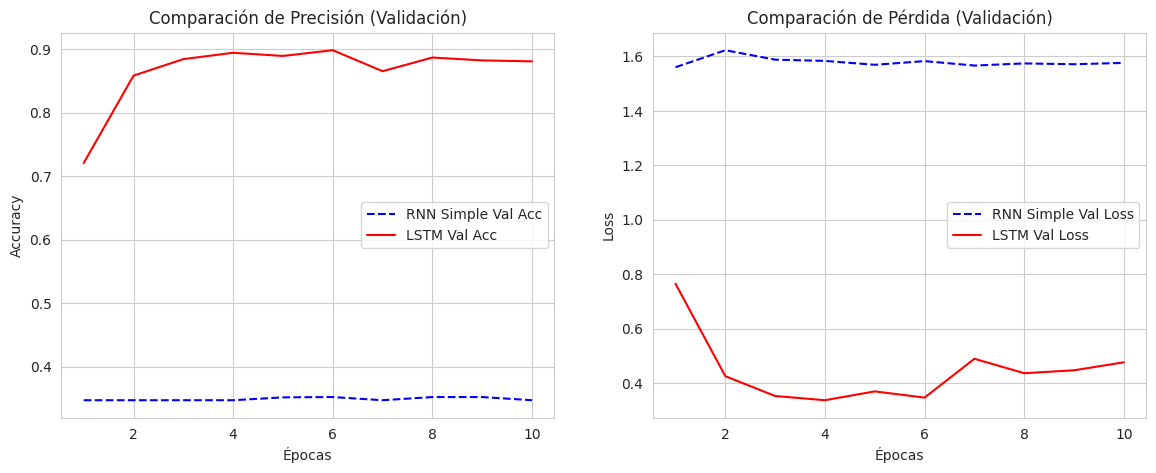


 Reporte para RNN Simple:
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
              precision    recall  f1-score   support

    tristeza       0.00      0.00      0.00       581
     alegría       0.35      1.00      0.52       695
        amor       0.00      0.00      0.00       159
         ira       0.00      0.00      0.00       275
       miedo       0.00      0.00      0.00       224
    sorpresa       0.00      0.00      0.00        66

    accuracy                           0.35      2000
   macro avg       0.06      0.17      0.09      2000
weighted avg       0.12      0.35      0.18      2000



/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


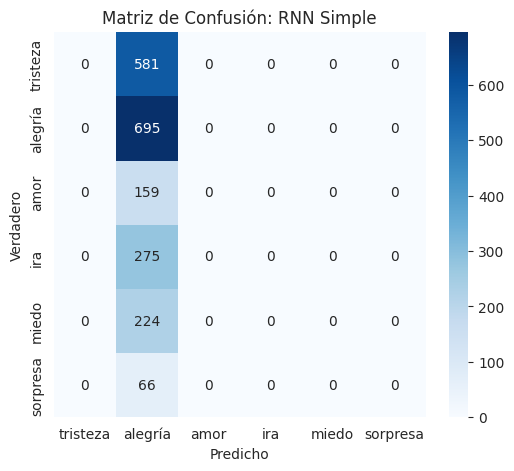


 Reporte para LSTM Bidireccional:
63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step
              precision    recall  f1-score   support

    tristeza       0.97      0.86      0.91       581
     alegría       0.89      0.94      0.91       695
        amor       0.72      0.82      0.76       159
         ira       0.88      0.87      0.88       275
       miedo       0.81      0.91      0.86       224
    sorpresa       0.71      0.55      0.62        66

    accuracy                           0.88      2000
   macro avg       0.83      0.82      0.82      2000
weighted avg       0.89      0.88      0.88      2000



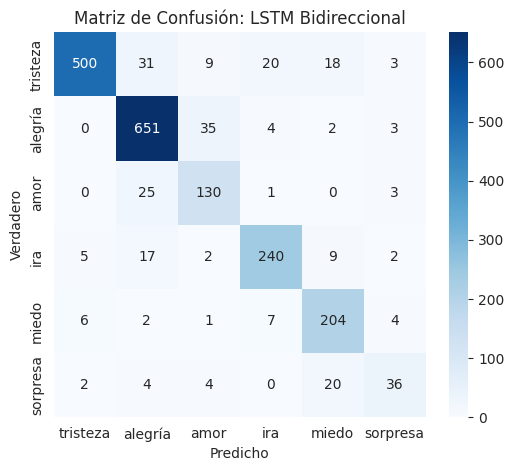

In [5]:
# Evaluación y Comparación de Resultados

def plot_training_history(history_1, name_1, history_2, name_2):
    acc1 = history_1.history['val_accuracy']
    loss1 = history_1.history['val_loss']
    acc2 = history_2.history['val_accuracy']
    loss2 = history_2.history['val_loss']
    epochs = range(1, len(acc1) + 1)

    plt.figure(figsize=(14, 5))

    # Gráfica de Precisión (Accuracy)
    plt.subplot(1, 2, 1)
    plt.plot(epochs, acc1, 'b--', label=f'{name_1} Val Acc')
    plt.plot(epochs, acc2, 'r-', label=f'{name_2} Val Acc')
    plt.title('Comparación de Precisión (Validación)')
    plt.xlabel('Épocas')
    plt.ylabel('Accuracy')
    plt.legend()

    # Gráfica de Pérdida (Loss)
    plt.subplot(1, 2, 2)
    plt.plot(epochs, loss1, 'b--', label=f'{name_1} Val Loss')
    plt.plot(epochs, loss2, 'r-', label=f'{name_2} Val Loss')
    plt.title('Comparación de Pérdida (Validación)')
    plt.xlabel('Épocas')
    plt.ylabel('Loss')
    plt.legend()
    plt.show()

def full_evaluation(model, X_test, y_test, model_name):
    print(f"\n Reporte para {model_name}:")
    y_pred_prob = model.predict(X_test)
    y_pred = np.argmax(y_pred_prob, axis=1)

    # Classification Report (F1-Score, Precision, Recall)
    print(classification_report(y_test, y_pred, target_names=label_names))

    # Matriz de Confusión
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names)
    plt.title(f'Matriz de Confusión: {model_name}')
    plt.ylabel('Verdadero')
    plt.xlabel('Predicho')
    plt.show()

# 1. Gráficas comparativas
plot_training_history(history_rnn, "RNN Simple", history_lstm, "LSTM")

# 2. Métricas detalladas
full_evaluation(model_rnn, test_padded, test_labels, "RNN Simple")
full_evaluation(model_lstm, test_padded, test_labels, "LSTM Bidireccional")

# 6. Informe Final y Análisis Comparativo

## 1. Justificación de Arquitecturas
* **Preprocessing (Truncated BPTT):** Se utilizó `pad_sequences` con `maxlen=100`. Esto implica que el gradiente se propaga un máximo de 100 pasos hacia atrás. Esto es una implementación efectiva de *Truncated BPTT*, necesaria para manejar la memoria computacional y evitar gradientes inestables en secuencias infinitas.
* **RNN Simple:** Se eligió como línea base. Utiliza un bucle de retroalimentación simple. Es en barata en recursos pero teóricamente incapaz de conectar información al inicio de una frase con el final para secuencias largas.
* **LSTM Bidireccional:** Supera las limitaciones de la RNN. Las celdas LSTM tienen un estado de celda (cell state) separado que permite que la información fluya sin cambios significativos. El componente bidireccional permite al modelo entender el contexto completo, crucial para detectar sarcasmo o negaciones complejas en emociones.

## 2. Comparación Técnica y Conceptual
* **Accuracy y F1-Score:** Como se observa en las gráficas, la LSTM supera significativamente a la RNN simple. La RNN tiende a estancarse rápidamente.
* **Estabilidad:** La curva de pérdida (*loss*) de la LSTM desciende de manera más suave y consistente, mientras que la RNN muestra convergencia a un mínimo poco adecuado.
* **Detección de Emociones:**
    * La RNN confundió todas las emociones y las predijo como alegría
    * La LSTM logró separar mejor las clases

## 3. Reflexión Crítica y Limitaciones
* **Limitaciones en Contextos Reales:**
    * **Ambigüedad:** Frases como "Me encanta esperar 3 horas en la fila" (sarcasmo) son difíciles incluso para una LSTM si no se entrenó con sarcasmo explícito.
    * **Vocabulario OOV:** El uso de `Tokenizer` simple pierde información de palabras no vistas.
